In [2]:
from pathlib import Path
import numpy as np
import pandas as pd

In [3]:
data = Path("data/loans.csv")

df = pd.read_csv(data)

df.head()

,assets,liabilities,income,credit_score,mortgage,status
0,0.210859,0.452865,0.281367,0.628039,0.302682,deny
1,0.395018,0.661153,0.330622,0.638439,0.502831,approve
2,0.291186,0.593432,0.438436,0.434863,0.315574,approve
3,0.458640,0.576156,0.744167,0.291324,0.394891,approve
4,0.463470,0.292414,0.489887,0.811384,0.566605,approve


<Axes: xlabel='credit_score', ylabel='mortgage'>

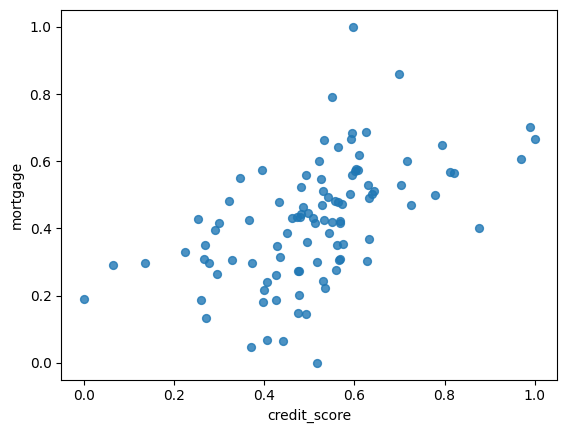

In [13]:
from matplotlib import pyplot as plt

df.plot(kind='scatter', x='credit_score', y='mortgage', s=32, alpha=.8)

<Axes: xlabel='liabilities', ylabel='income'>

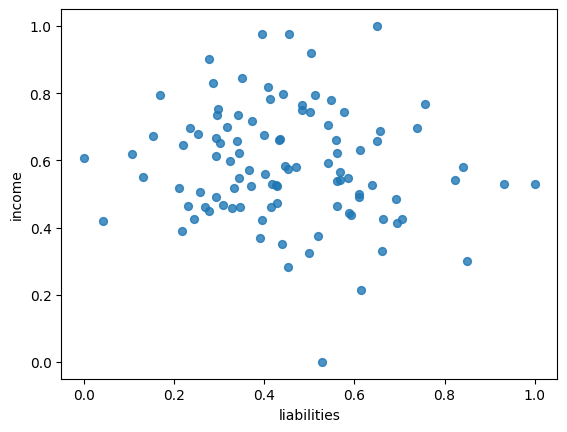

In [14]:

df.plot(kind='scatter', x='liabilities', y='income', s=32, alpha=.8)


<Axes: ylabel='status'>

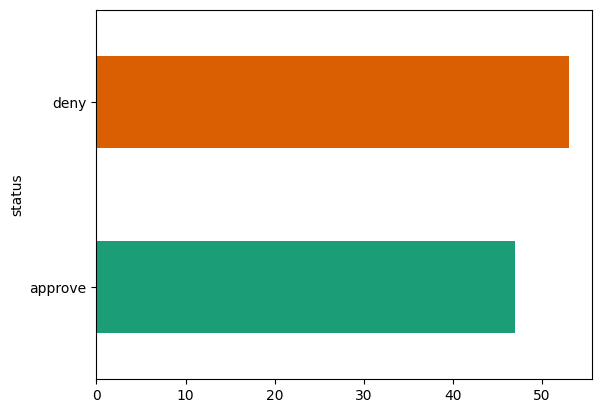

In [15]:

df.groupby('status').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))


In [16]:
#Separate Targets

y = df["status"]
x = df.drop(columns = "status")

In [17]:
#Splitting Data in Train and Test

from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test = train_test_split(x , y , random_state = 1 , stratify = y)

x_train.shape

(75, 5)

In [48]:
#Creating a logistic regression Classification (Linear)

from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(solver = "lbfgs",max_iter=100 , random_state=1)
classifier

LogisticRegression(max_iter=1, random_state=1)

In [49]:
classifier.fit(x_train , y_train)

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1, random_state=1)

In [50]:
#Scoring our model

print(f"Trained Data Score is: {classifier.score(x_train , y_train)} ")
print(f"Tested Data Score is: {classifier.score(x_test , y_test)}")

Trained Data Score is: 0.5333333333333333 
Tested Data Score is: 0.52


In [23]:
#Making Predictions Using our data

prediction = classifier.predict(x_test)

results = pd.DataFrame({"Prediction" :prediction , "Actual" : y_test}).reset_index(drop = True)

results.head(15)

,Prediction,Actual
0,deny,deny
1,deny,approve
2,deny,deny
3,approve,deny
4,deny,deny
5,deny,approve
6,deny,deny
7,approve,deny
8,deny,deny
9,approve,approve


<Axes: ylabel='Actual'>

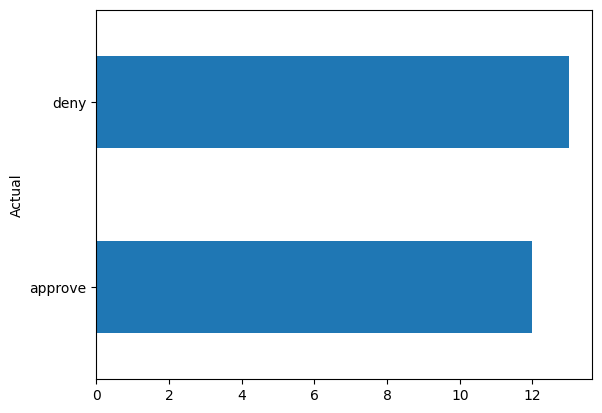

In [39]:
results.groupby('Actual').size().plot(kind='barh')

<Axes: ylabel='Prediction'>

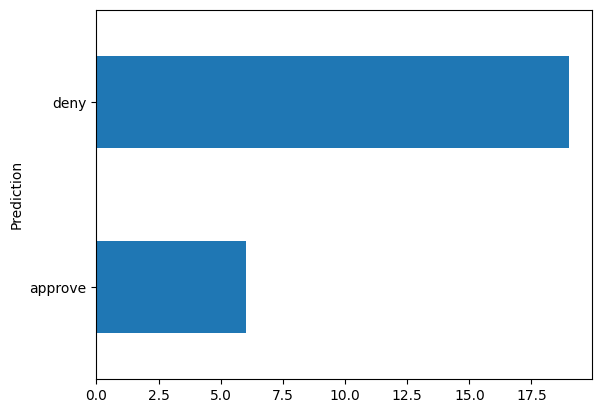

In [35]:
results.groupby('Prediction').size().plot(kind='barh')

**Our Predicted data is very bad and has low accuracy**

In [40]:
#Classification Matrix

from sklearn.metrics import confusion_matrix

confusion_matrix(y_test , prediction)

array([[ 3,  9],
       [ 3, 10]])

In [41]:
#Confusuion Report

from sklearn.metrics import classification_report

print(classification_report(y_test , prediction))

              precision    recall  f1-score   support

     approve       0.50      0.25      0.33        12
        deny       0.53      0.77      0.62        13

    accuracy                           0.52        25
   macro avg       0.51      0.51      0.48        25
weighted avg       0.51      0.52      0.48        25



In [52]:
#Creating logistic regression classification (SVM)
from sklearn.svm import SVC
import matplotlib.pyplot as plt
from matplotlib import style
style.use("ggplot")


classifier_svc = SVC(kernel = 'linear')
classifier_svc

SVC(kernel='linear')

In [53]:
classifier_svc.fit(x_train , y_train)

SVC(kernel='linear')

In [54]:
#Scoring our model (SVC)

print(f"Trained Data Score is: {classifier_svc.score(x_train , y_train)} ")
print(f"Tested Data Score is: {classifier_svc.score(x_test , y_test)}")

Trained Data Score is: 0.6133333333333333 
Tested Data Score is: 0.6


In [65]:
#Making Predictions Using our data (SVC)

prediction_svc = classifier_svc.predict(x_test)

results_svc = pd.DataFrame({"Prediction" :prediction_svc , "Actual" : y_test}).reset_index(drop = True)

results_svc.head(15)

,Prediction,Actual
0,approve,deny
1,deny,approve
2,deny,deny
3,approve,deny
4,deny,deny
5,approve,approve
6,approve,deny
7,approve,deny
8,deny,deny
9,approve,approve


<Axes: ylabel='Prediction'>

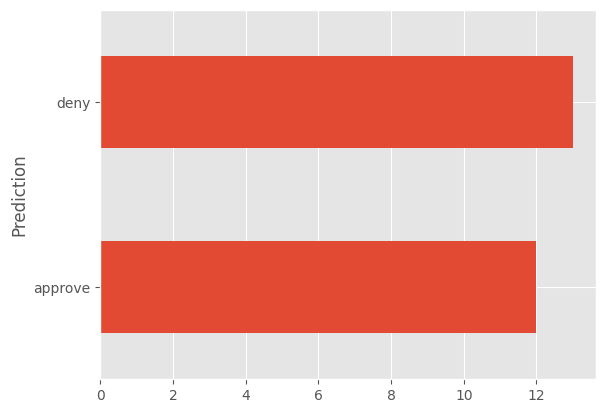

In [60]:
results_svc.groupby('Prediction').size().plot(kind='barh')

<Axes: ylabel='Actual'>

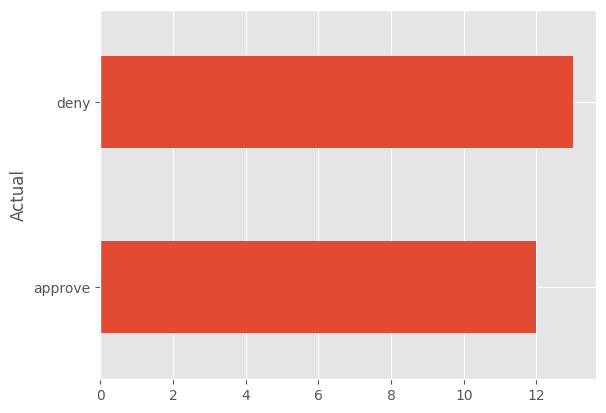

In [61]:
results_svc.groupby('Actual').size().plot(kind='barh')

In [66]:
#Confusuion Report (SVC)

from sklearn.metrics import classification_report

print(classification_report(y_test , prediction_svc))

              precision    recall  f1-score   support

     approve       0.58      0.58      0.58        12
        deny       0.62      0.62      0.62        13

    accuracy                           0.60        25
   macro avg       0.60      0.60      0.60        25
weighted avg       0.60      0.60      0.60        25



In [ ]:
#1:52:00